# BRASA · Reto avanzado: posibles focos de fuego activo

Este cuaderno recorre paso a paso la detección de actividad aparente en la adquisición. La cicatriz afectada se conserva en naranja; los candidatos activos se muestran en magenta.

El detector adapta el SWIR-rule descrito por Mitra et al., arXiv:2609.16199v1, ecuaciones 2–4. El paper aplica los umbrales a reflectancias antes del render. Aquí solo tenemos JPEG de visualización, así que invertir el render fijo B12/B11/B8A produce valores aproximados, cuantizados y con pérdida. Los focos son indicios cromáticos, no temperatura medida ni fuego confirmado.

Se añade contraste contextual con los mismos parámetros para todas las escenas. El orden de bandas y el render de los JPEG no están verificados; no se recuperan reflectancias medidas. Escala declarada: **20 m/píxel original**.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, json
import numpy as np
import cv2
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
if (ROOT / "backend").is_dir():
    BACKEND = ROOT / "backend"
elif (ROOT / "processing").is_dir():
    BACKEND = ROOT
else:
    raise RuntimeError("Abre el cuaderno desde la raíz del proyecto o desde backend.")
sys.path.insert(0, str(BACKEND))
from processing import analyze, SegmentationConfig
from processing.active_fire import ActiveFireConfig, detect_active_fire
from processing.io import read_rgb

plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
SCENE = "Niebla"  # Cambia a "La_Mierla" o "Madrid-Avila"
CONFIG = SegmentationConfig(max_side=1536, sensitivity=0.5, refine=True, pixel_size_m=20)
folder = BACKEND / "images" / SCENE
swir, original_size = read_rgb(folder / "image_SWIR.jpg")
visible, visible_size = read_rgb(folder / "image_True_color.jpg")
assert original_size == visible_size, "Las imágenes deben compartir cuadrícula."
result = analyze(swir, visible, CONFIG, original_size=original_size, active_fire=True)
fire = result["active_fire"]

print("Escena:", SCENE)
print("Tamaño original:", original_size)
print("Tamaño de análisis:", result["analysis_size"])
print("Superficie afectada (máscara naranja):", result["stats"]["affected_percent"], "%")
print("Píxeles y focos activos posibles:", fire["stats"]["active_pixels"], "/", fire["stats"]["hotspot_count"])
print("Configuración SWIR:", json.dumps(fire["config"], indent=2))
print("Área afectada estimada (ha):", result["stats"]["affected_area_hectares_estimated"])
print("Perímetro exterior estimado (m):", result["stats"]["perimeter_m_estimated"])
print("Calidad:", json.dumps(result["quality"], ensure_ascii=False, indent=2))

Escena: Niebla
Tamaño original: (2500, 1546)
Tamaño de análisis: {'width': 2500, 'height': 1546}
Superficie afectada (máscara naranja): 4.624 %
Píxeles y focos activos posibles: 9204 / 36
Configuración SWIR: {
  "b12_seed": 0.35,
  "ratio_seed": 4.0,
  "b12_candidate": 0.25,
  "ratio_candidate": 2.0,
  "b12_render_max": 0.6,
  "b8a_render_max": 0.45,
  "growth_steps": 2,
  "min_component_pixels": 2,
  "contextual_filter": true,
  "context_radius_fraction": 0.015,
  "min_red_excess": 0.08,
  "min_context_z": 1.5
}
Área afectada estimada (ha): 7148.36
Perímetro exterior estimado (m): 212096.65
Calidad: {
  "status": "usable",
  "uninformative": false,
  "checks": [
    {
      "id": "information",
      "label": "Información de la composición",
      "status": "ok",
      "detail": "La composición contiene variación espacial utilizable."
    },
    {
      "id": "alignment",
      "label": "Correspondencia espacial",
      "status": "ok",
      "detail": "Coincidencia geométrica: 182 pun

## 1. Entradas y cicatriz afectada

Ambas composiciones comparten el encuadre. True Color aporta contexto visual y la máscara de la cicatriz que se calculó con el reto básico; SWIR es la entrada del detector avanzado. La imagen Wildfires, cuando existe, se presenta solo como contexto visual.

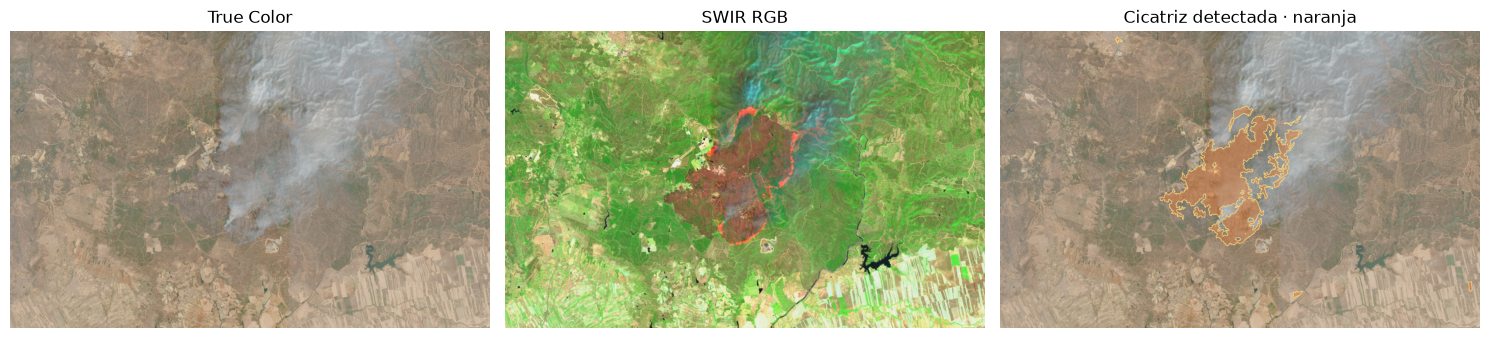

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, image, title in zip(axes, [result["true_rgb"], result["swir_rgb"], result["overlay"]],
                            ["True Color", "SWIR RGB", "Cicatriz detectada · naranja"]):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Aproximar los canales SWIR del paper

Se asume que el JPEG almacena B12, B11 y B8A en sus canales rojo, verde y azul. Con los límites de render publicados en el paper, aproximamos B12 = 0,60 × R/255 y B8A = 0,45 × B/255. El contraste q es B12/B8A. La compresión JPEG y la cuantización impiden reconstruir las reflectancias originales con exactitud.

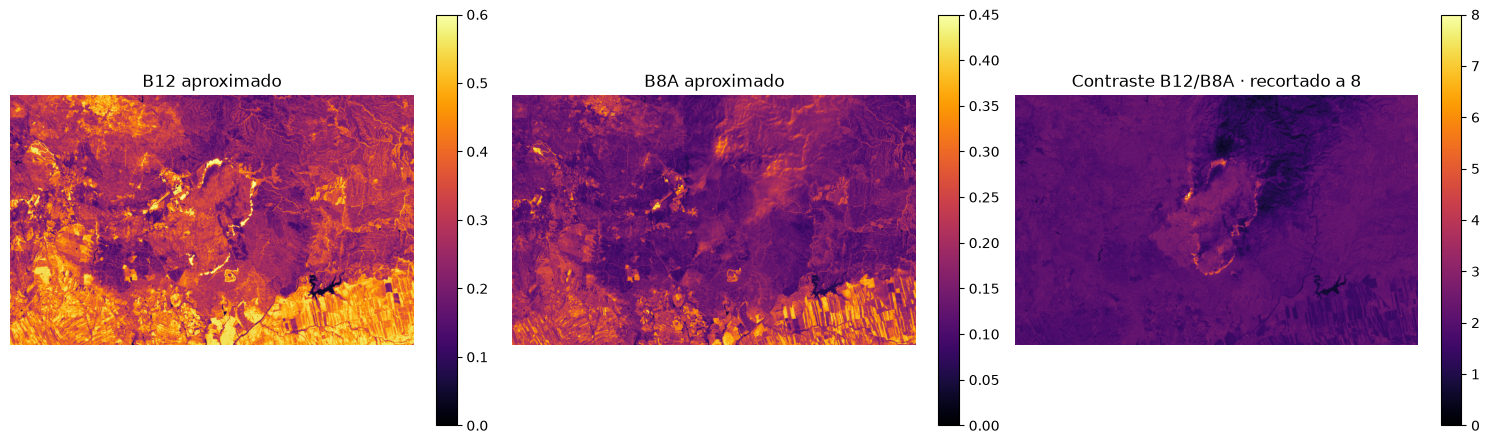

Estos valores dependen del orden de canales y del render SWIR.


In [3]:
active_config = ActiveFireConfig()
rgb = result["swir_rgb"].astype(np.float32)
b12_approx = active_config.b12_render_max * rgb[:, :, 0] / 255.0
b8a_approx = active_config.b8a_render_max * rgb[:, :, 2] / 255.0
q_approx = np.divide(b12_approx, b8a_approx, out=np.full_like(b12_approx, np.inf), where=b8a_approx > 1e-6)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, data, title, vmax in [
    (axes[0], b12_approx, "B12 aproximado", 0.60),
    (axes[1], b8a_approx, "B8A aproximado", 0.45),
    (axes[2], np.minimum(q_approx, 8), "Contraste B12/B8A · recortado a 8", 8),
]:
    im = ax.imshow(data, cmap="inferno", vmin=0, vmax=vmax)
    ax.set_title(title)
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()
print("Estos valores dependen del orden de canales y del render SWIR.")

## 3. Semillas fuertes y candidatos

La regla usa dos condiciones por píxel. La semilla requiere B12 ≥ 0,35 y q ≥ 4. Un candidato requiere B12 ≥ 0,25 y q ≥ 2. Las semillas dan especificidad; los candidatos permiten que el foco se extienda alrededor de una semilla.

Estos umbrales generan semillas cromáticas iniciales. Antes de crecer, cada componente debe contener al menos una semilla con contraste local suficiente, como se muestra a continuación.

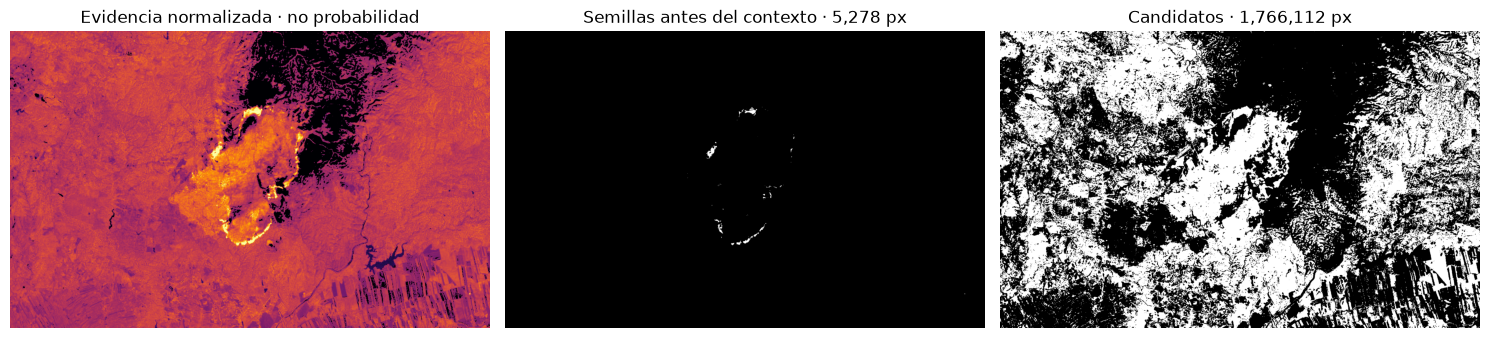

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(fire["score"], cmap="inferno", vmin=0, vmax=1)
axes[0].set_title("Evidencia normalizada · no probabilidad")
axes[1].imshow(fire["raw_seeds"], cmap="gray")
axes[1].set_title(f"Semillas antes del contexto · {fire['stats']['raw_seed_pixels']:,} px")
axes[2].imshow(fire["candidates"], cmap="gray")
axes[2].set_title(f"Candidatos · {fire['stats']['candidate_pixels']:,} px")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

### 3b. Rechazar superficies rojas uniformes mediante contraste local

En una ventana de radio relativo al tamaño de la imagen se estima el rojo medio y su desviación del fondo, excluyendo semillas e incertidumbre. Una semilla recibe apoyo si supera la media en 0,08 (escala 0–1), presenta z ≥ 1,5 con suelo de ruido 0,015 y dispone de al menos un 25% de fondo en la ventana. Se conserva el componente completo si alguna semilla recibe apoyo.

Esto evita clasificar toda una superficie roja uniforme y conserva objetivos pequeños. Puede mantener suelos rojos con bordes brillantes u omitir frentes muy extensos: la reducción de candidatos **no demuestra una mejora de precisión** sin etiquetas independientes.

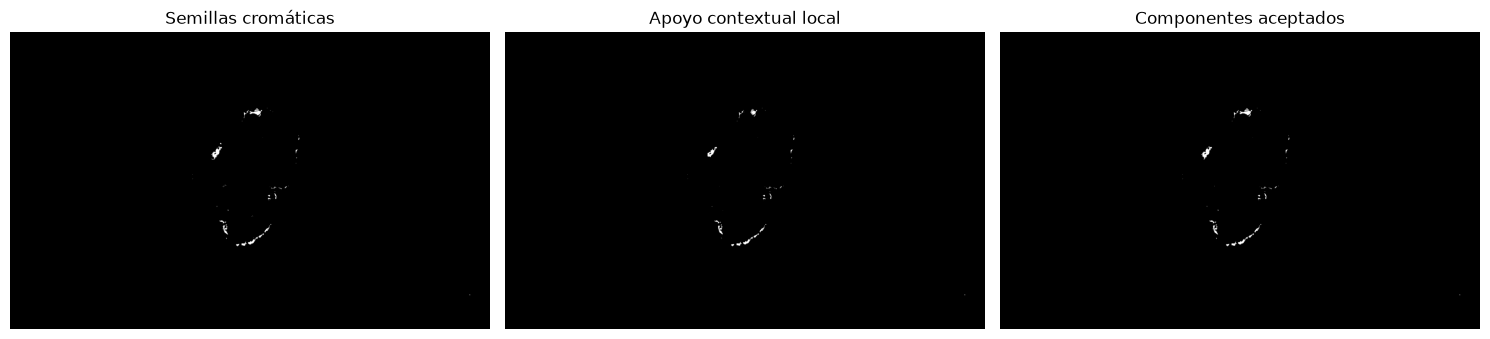

Focos candidatos antes/después: 44 36
Semillas descartadas: 109
Esta diferencia no mide falsos positivos reales.


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, image, title in zip(axes, [fire["raw_seeds"], fire["context_support"], fire["seeds"]],
                            ["Semillas cromáticas", "Apoyo contextual local", "Componentes aceptados"]):
    ax.imshow(image, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
without_context = detect_active_fire(result["swir_rgb"], result["uncertain"], original_size,
                                     ActiveFireConfig(contextual_filter=False))
print("Focos candidatos antes/después:", without_context["stats"]["hotspot_count"], fire["stats"]["hotspot_count"])
print("Semillas descartadas:", fire["stats"]["rejected_seed_pixels"])
print("Esta diferencia no mide falsos positivos reales.")

## 4. Crecimiento limitado y filtro de motas

Desde cada semilla se permiten hasta dos pasos en cruz (vecindad de cuatro píxeles), siempre dentro de los candidatos. A continuación se descartan componentes de un solo píxel conectados por vecindad de ocho. El crecimiento limitado evita que toda una región cromáticamente parecida se convierta en un gran foco.

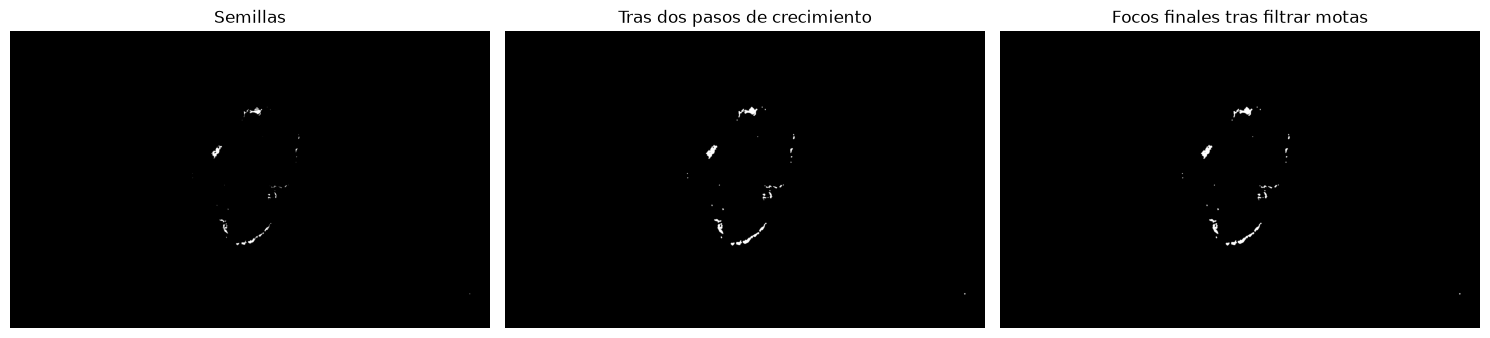

{
  "raw_seed_pixels": 5278,
  "rejected_seed_pixels": 109,
  "seed_pixels": 5169,
  "candidate_pixels": 1766112,
  "active_pixels": 9204,
  "active_percent": 0.2381,
  "hotspot_count": 36,
  "active_area_hectares_estimated": 368.16
}


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, image, title in [
    (axes[0], fire["seeds"], "Semillas"),
    (axes[1], fire["grown"], "Tras dos pasos de crecimiento"),
    (axes[2], fire["mask"], "Focos finales tras filtrar motas"),
]:
    ax.imshow(image, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
print(json.dumps(fire["stats"], ensure_ascii=False, indent=2))

## 5. Separar actividad aparente de superficie afectada

El naranja representa la superficie detectada como afectada. El magenta representa componentes compatibles con fuego activo en el momento de la adquisición. La etiqueta descargable avanzada conserva ambas clases: 1 = afectada sin foco activo detectado, 2 = posible actividad, 0 = fondo y 255 = incierto/sin datos.

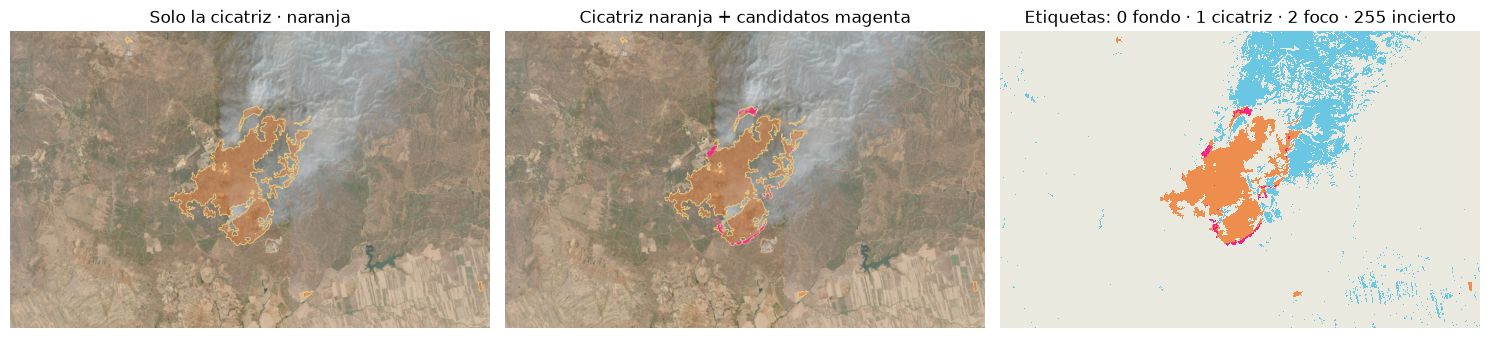

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(result["overlay"])
axes[0].set_title("Solo la cicatriz · naranja")
axes[1].imshow(fire["overlay"])
axes[1].set_title("Cicatriz naranja + candidatos magenta")
labels = fire["labels"].copy()
display_labels = labels.astype(np.float32)
display_labels[labels == 255] = 3
cmap = plt.matplotlib.colors.ListedColormap(["#e9e9df", "#ed8d4e", "#f42389", "#69c7e4"])
axes[2].imshow(display_labels, cmap=cmap, vmin=0, vmax=3, interpolation="nearest")
axes[2].set_title("Etiquetas: 0 fondo · 1 cicatriz · 2 foco · 255 incierto")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Centros y atributos de los focos

Cada componente conectado produce un centro, una caja, un área aproximada y el número de píxeles semilla. Las coordenadas se expresan en píxeles de la imagen original; sin georreferenciación no equivalen a latitud/longitud. La lista muestra los 20 focos ordenados por semillas y tamaño.

In [8]:
print("Resumen:", json.dumps(fire["stats"], ensure_ascii=False, indent=2))
rows = fire["hotspots"][:20]
if rows:
    header = "| ID | x (px) | y (px) | área (ha aprox.) | semillas | B12/B8A máx. aprox. |\n|---:|---:|---:|---:|---:|---:|"
    body = "\n".join(f"| {h['id']} | {h['centroid'][0]} | {h['centroid'][1]} | {h['area_hectares_estimated']} | {h['seed_pixels']} | {h['peak_b12_b8a_ratio_approx']} |" for h in rows)
    display(Markdown(header + "\n" + body))
else:
    print("No hay focos candidatos con estos umbrales; no es prueba de ausencia de actividad.")

Resumen: {
  "raw_seed_pixels": 5278,
  "rejected_seed_pixels": 109,
  "seed_pixels": 5169,
  "candidate_pixels": 1766112,
  "active_pixels": 9204,
  "active_percent": 0.2381,
  "hotspot_count": 36,
  "active_area_hectares_estimated": 368.16
}


| ID | x (px) | y (px) | área (ha aprox.) | semillas | B12/B8A máx. aprox. |
|---:|---:|---:|---:|---:|---:|
| 1 | 1075.4 | 626.4 | 71.24 | 1243 | 46.133 |
| 2 | 1271.03 | 418.41 | 78.44 | 1178 | 7.772 |
| 3 | 1276.53 | 1079.85 | 48.96 | 748 | 6.536 |
| 4 | 1121.44 | 1026.22 | 37.28 | 530 | 7.504 |
| 5 | 1218.48 | 1103.16 | 17.4 | 266 | 5.701 |
| 6 | 1340.98 | 1023.74 | 20.08 | 263 | 6.211 |
| 7 | 1107.36 | 986.55 | 13.84 | 182 | 9.697 |
| 8 | 1382.87 | 853.87 | 11.4 | 135 | 5.486 |
| 9 | 1185.15 | 1107.29 | 8.92 | 124 | 6.123 |
| 10 | 1490.7 | 619.34 | 7.68 | 84 | 4.658 |
| 11 | 1349.9 | 866.42 | 5.64 | 70 | 6.316 |
| 12 | 1348.93 | 850.98 | 4.92 | 59 | 6.173 |
| 13 | 1378.41 | 809.44 | 5.32 | 47 | 4.789 |
| 14 | 1435.49 | 807.08 | 4.32 | 43 | 5.271 |
| 15 | 1504.07 | 554.2 | 4.4 | 42 | 4.253 |
| 16 | 1407.47 | 812.61 | 4.6 | 34 | 5.484 |
| 17 | 1363.4 | 812.03 | 2.32 | 18 | 4.5 |
| 18 | 1135.25 | 926.89 | 2.28 | 15 | 4.973 |
| 19 | 1126.69 | 1073.4 | 2.2 | 15 | 4.507 |
| 20 | 1492.09 | 654.0 | 1.76 | 12 | 4.325 |

## 7. Contraste visual de la escena, si está disponible

La carpeta contiene una composición Wildfires para Niebla y La Mierla. Se muestra junto al resultado para inspección visual; no se convierte en máscara ni se usa para calcular exactitud, ya que no es una etiqueta por píxel independiente.

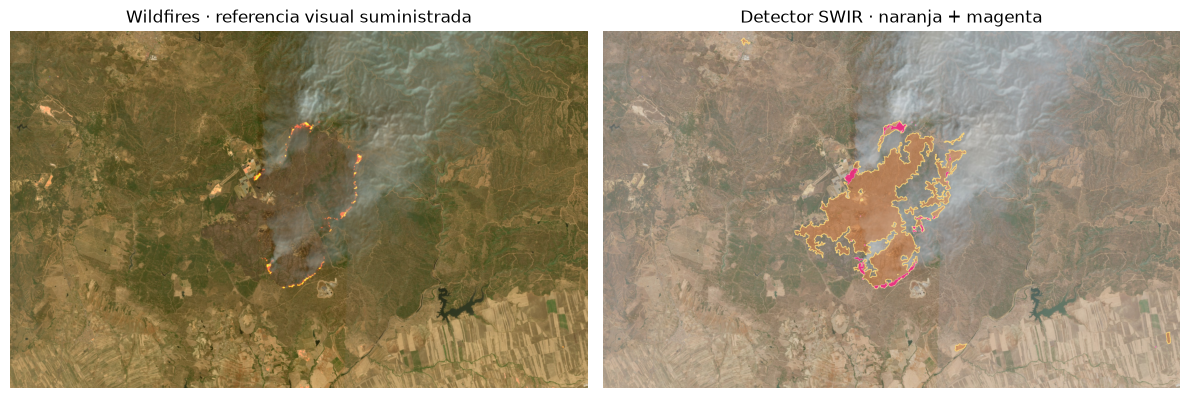

In [9]:
reference_path = folder / "image_Wildfires.jpg"
if reference_path.is_file():
    reference, reference_size = read_rgb(reference_path)
    if reference_size == original_size:
        reference = cv2.resize(reference, (result["analysis_size"]["width"], result["analysis_size"]["height"]))
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        axes[0].imshow(reference)
        axes[0].set_title("Wildfires · referencia visual suministrada")
        axes[1].imshow(fire["overlay"])
        axes[1].set_title("Detector SWIR · naranja + magenta")
        for ax in axes:
            ax.axis("off")
        plt.tight_layout()
        plt.show()
    else:
        print("La composición Wildfires no comparte el tamaño original; se omite la comparación.")
else:
    print("Esta escena no incluye image_Wildfires.jpg; no hay referencia visual adicional.")

## Límites de interpretación

- El umbral del paper se aplica a reflectancias convertidas; aquí usamos una aproximación inversa de la escala visual JPEG.
- Hay que verificar que la composición sea SWIR RGB en orden B12/B11/B8A. Otras combinaciones requieren ajustar la regla.
- Un candidato puede deberse a suelo, ruido, saturación, nubes o diferencias de render; no mide temperatura ni confirma combustión.
- La composición Wildfires solo aporta contexto visual y no es una máscara de verdad terreno.
- La detección de focos se ejecuta con la misma función que usa FastAPI.
- La escala métrica procede del dato declarado de 20 m por píxel original y compensa el remuestreo.
- La evaluación reproducible y sus límites están en `evaluation/latest/report.md` y en `temporal_evaluacion.ipynb`.